In [13]:
from pathlib import Path
from transformers import GPT2LMHeadModel, GPT2Tokenizer
from peft import PeftModel

project_root = Path.cwd()

# Notebooks usually run with the notebook/ folder as cwd
if not (project_root / "checkpoints" / "lora_step1").exists():
    project_root = project_root.parent

checkpoint = project_root / "checkpoints" / "lora_step1"

print("Checkpoint:", checkpoint)

if not (checkpoint / "adapter_config.json").exists():
    raise FileNotFoundError(
        f"adapter_config.json is missing from {checkpoint}"
    )

tokenizer = GPT2Tokenizer.from_pretrained("distilgpt2")
tokenizer.pad_token = tokenizer.eos_token

base_model = GPT2LMHeadModel.from_pretrained("distilgpt2")
model = PeftModel.from_pretrained(base_model, str(checkpoint))
model.eval()

print("Model loaded.")

Checkpoint: c:\Users\HUBERT LABRADA\Documents\SCHOOL\3rd YR\1st sem\NLP\Project\Teaching-an-LLM-with-Cebuano\checkpoints\lora_step1


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

c:\Users\HUBERT LABRADA\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\HUBERT LABRADA\.cache\huggingface\hub\models--distilgpt2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

... (4 outputs left out)

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Skipping import of cpp extensions due to incompatible torch version. Please upgrade to torch >= 2.11.0 (found 2.10.0+cpu).
W1121 20:55:13.955000 25836 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Model loaded.


In [19]:
import torch, json

project_root = Path.cwd().parent

prompts = [
    "Ang mga estudyante sa Cebu",
    "Nagsugod na ang",
    "Ang kinabuhi sa",
    "Miadto siya sa merkado",
    "Sa matag adlaw ang mga tawo",
]

def generate(prompt, model, tokenizer, **kwargs):
    inputs = tokenizer(prompt, return_tensors="pt")
    with torch.no_grad():
        output = model.generate(
            inputs["input_ids"],
            max_new_tokens=60,
            pad_token_id=tokenizer.eos_token_id,
            **kwargs
        )
    new_tokens = output[0][inputs["input_ids"].shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True)

all_results = {}

for prompt in prompts:
    print(f"\n{'='*65}")
    print(f"PROMPT: {prompt}")
    print('='*65)

    greedy = generate(prompt, model, tokenizer, do_sample=False)
    topk = generate(prompt, model, tokenizer, do_sample=True, top_k=50, temperature=0.8)
    topp = generate(prompt, model, tokenizer, do_sample=True, top_p=0.92, temperature=0.8)
    beam = generate(prompt, model, tokenizer, do_sample=False, num_beams=4, early_stopping=True)

    print(f"\n[GREEDY]\n{greedy}")
    print(f"\n[TOP-K]\n{topk}")
    print(f"\n[NUCLEUS]\n{topp}")
    print(f"\n[BEAM SEARCH]\n{beam}")

    all_results[prompt] = {
        "greedy": greedy, "top_k": topk,
        "nucleus": topp, "beam": beam
    }

with open( project_root / "output" / "decoding_outputs.json", "w", encoding="utf-8") as f:
    json.dump(all_results, f, ensure_ascii=False, indent=2)


PROMPT: Ang mga estudyante sa Cebu

[GREEDY]
yan.


Nagatay ang mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga

[TOP-K]
ayanas sa mga estudyante sa mga mga alga takotakayin sa mga maganadan sa pungayon sa mga alga mga nga pagadan sa mga takotakayin sa mga pagad

[NUCLEUS]
co.

Mang-agadat nga mga mga nga mga nga mga mga kannayan ang mga mga og mga nga mga mga lansak ka kannayan sa nga mga kann

[BEAM SEARCH]
yan.



Nga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga m

PROMPT: Nagsugod na ang

[GREEDY]
 mga nga nga nga nga nga nga nga nga nga nga nga nga nga nga nga nga nga nga nga nga nga nga nga nga nga nga nga nga nga

[TOP-K]
 gani nga rga pamilyon nga pagkon nga iyang nga mga nga nga nga mga nga kapitay nga dang ka sa maggapitay sa diasod nga mga nga kakad

[NUCLEUS]
 ig mga siya kungang nga mga dasyod nga nga nga siya kang na pag-yungod sa tayin ni ang sa mga nga kakapan

In [20]:
# Greedy should be identical every run
print("GREEDY — should be same every time:")
for i in range(3):
    print(f"  Run {i+1}: {generate(prompts[0], model, tokenizer, do_sample=False)}")

# Top-K should differ
print("\nTOP-K — should vary:")
for i in range(3):
    print(f"  Run {i+1}: {generate(prompts[0], model, tokenizer, do_sample=True, top_k=50, temperature=0.8)}")

GREEDY — should be same every time:
  Run 1: yan.


Nagatay ang mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga
  Run 2: yan.


Nagatay ang mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga
  Run 3: yan.


Nagatay ang mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga mga

TOP-K — should vary:
  Run 1: il ng Nga Diliang ang Ang Miliangon , nga nagakay .

Mualo nga deutadon sa Kamion , ug mga diklamang mga ako sa Diliang City City Council on Wednesday.

  Run 2: ya .
Dawabong ko mga nga nga pagkung sa Ngayon sa nga pagkimosay sa Ngayon.

Pilagodo sa mga nganan nga tenga sa kapangay ang mga
  Run 3: yan, og tenglumion sa mga pangatong tenglumion ang ang kusumot.

Wee kon kinang ang nga mga mga niang kalag sa kungo sa mga nga mga


In [23]:
import time

project_root = Path.cwd().parent

def benchmark_generation(prompt, model, tokenizer,
                          use_cache, n_tokens=100, n_runs=5):
    inputs = tokenizer(prompt, return_tensors="pt")
    times = []
    for run in range(n_runs):
        start = time.perf_counter()
        with torch.no_grad():
            model.generate(
                inputs["input_ids"],
                max_new_tokens=n_tokens,
                do_sample=False,
                use_cache=use_cache,
                pad_token_id=tokenizer.eos_token_id,
            )
        elapsed = time.perf_counter() - start
        times.append(elapsed)
        print(f"  Run {run+1}: {elapsed:.3f}s (cache={'ON' if use_cache else 'OFF'})")
    return sum(times) / len(times)

test_prompt = "Ang mga tawo sa dakbayan nagpuyo"
token_counts = [50, 100, 150]
benchmark_results = {}

for n in token_counts:
    print(f"\n--- {n} tokens ---")
    print("WITH cache:")
    cached = benchmark_generation(test_prompt, model, tokenizer, use_cache=True, n_tokens=n)
    print("WITHOUT cache:")
    uncached = benchmark_generation(test_prompt, model, tokenizer, use_cache=False, n_tokens=n)
    speedup = uncached / cached
    benchmark_results[n] = {"cached_avg": cached, "uncached_avg": uncached, "speedup": speedup}
    print(f"→ {speedup:.2f}x speedup")

import json
with open(project_root / "output" / "kvcache_benchmark.json", "w") as f:
    json.dump(benchmark_results, f, indent=2)


--- 50 tokens ---
WITH cache:
  Run 1: 2.076s (cache=ON)
  Run 2: 1.037s (cache=ON)
  Run 3: 1.089s (cache=ON)
  Run 4: 0.930s (cache=ON)
  Run 5: 1.017s (cache=ON)
WITHOUT cache:
  Run 1: 1.738s (cache=OFF)
  Run 2: 1.636s (cache=OFF)
  Run 3: 1.656s (cache=OFF)
  Run 4: 1.561s (cache=OFF)
  Run 5: 1.596s (cache=OFF)
→ 1.33x speedup

--- 100 tokens ---
WITH cache:
  Run 1: 2.001s (cache=ON)
  Run 2: 1.936s (cache=ON)
  Run 3: 2.023s (cache=ON)
  Run 4: 2.089s (cache=ON)
  Run 5: 2.170s (cache=ON)
WITHOUT cache:
  Run 1: 3.904s (cache=OFF)
  Run 2: 3.830s (cache=OFF)
  Run 3: 3.893s (cache=OFF)
  Run 4: 3.800s (cache=OFF)
  Run 5: 3.835s (cache=OFF)
→ 1.89x speedup

--- 150 tokens ---
WITH cache:
  Run 1: 2.625s (cache=ON)
  Run 2: 2.672s (cache=ON)
  Run 3: 2.662s (cache=ON)
  Run 4: 3.278s (cache=ON)
  Run 5: 3.178s (cache=ON)
WITHOUT cache:
  Run 1: 7.509s (cache=OFF)
  Run 2: 7.483s (cache=OFF)
  Run 3: 8.072s (cache=OFF)
  Run 4: 7.403s (cache=OFF)
  Run 5: 7.854s (cache=OFF)
→ 2

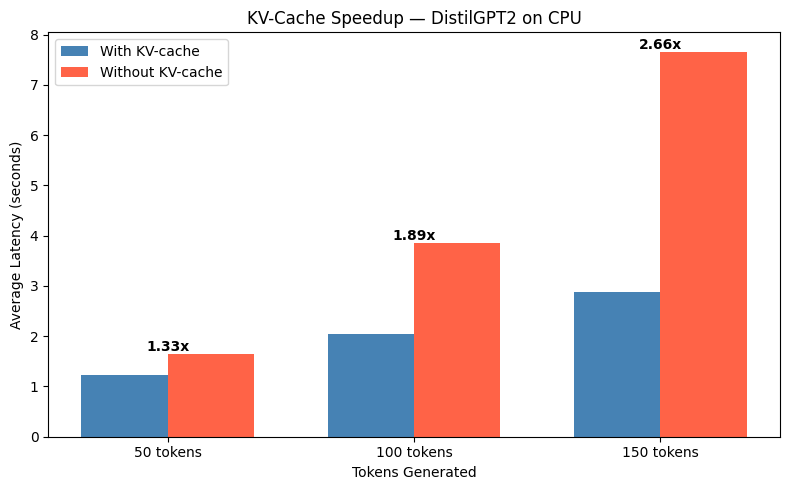

In [25]:
import matplotlib.pyplot as plt

project_root = Path.cwd().parent

tokens = list(benchmark_results.keys())
cached_times = [benchmark_results[n]['cached_avg'] for n in tokens]
uncached_times = [benchmark_results[n]['uncached_avg'] for n in tokens]

x = range(len(tokens))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar([i - width/2 for i in x], cached_times, width, label='With KV-cache', color='steelblue')
ax.bar([i + width/2 for i in x], uncached_times, width, label='Without KV-cache', color='tomato')

ax.set_xlabel("Tokens Generated")
ax.set_ylabel("Average Latency (seconds)")
ax.set_title("KV-Cache Speedup — DistilGPT2 on CPU")
ax.set_xticks(list(x))
ax.set_xticklabels([f"{n} tokens" for n in tokens])
ax.legend()

for i, n in enumerate(tokens):
    speedup = benchmark_results[n]['speedup']
    ax.annotate(f"{speedup:.2f}x",
                xy=(i, max(cached_times[i], uncached_times[i])),
                ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig( project_root / "output" / "kvcache_benchmark.png", dpi=150)
plt.show()